In [1]:
## time line of events

## figure outline

## A: EDM disp
## B: SPOT disp mag L1888, L1931
## C: InSAR on L1948 (fringes, no fringes, incoherence) (S1, TSX 96, TSX 134, CSK)
## D: InSAR on L1931 (fringes, no fringes, incoherence) (S1, TSX 96, TSX 134, CSK)
## E: coherence on western flank (S1, TSX 96, TSX 134, CSK)
## F: lava dome volume and extrusion rate


## steps:
##
## 1: load dependencies
## 2: load relevant data
## 3: plot results

In [2]:
## 1 load dependencies


## first time series test
# append ../../ to make link to main repo work
import sys
sys.path.append('../../')
sys.path.append('/Applications/anaconda3/envs/PhD_clean/lib/python3.11/site-packages/')


# import external packages
import numpy as np
import pandas as pd
import numba
from numba import vectorize
import glob # for file search
import copy
import os # operating system stuff
import re # regex


import geopandas as gpd
import rasterio as rio
import rasterio.mask
from rasterio.plot import plotting_extent
# import rioxarray
from shapely.geometry import Polygon
from shapely.geometry.point import Point
import pyproj
from pyproj import CRS
from inpoly import inpoly2 # for fast inpolygon checks
import utm

import matplotlib.pyplot as plt 
import matplotlib.dates as mdates
from matplotlib import cm as mpl_cm
from matplotlib import colors as mcolors 
import matplotlib.image as mplimg

from mpl_toolkits.axes_grid1 import make_axes_locatable # for colorbar scaling
from mpl_toolkits.axes_grid1 import ImageGrid
from matplotlib_scalebar.scalebar import ScaleBar
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import FormatStrFormatter

import seaborn as sns
from matplotlib import rc_file_defaults
rc_file_defaults()
# sns.set(style=None, color_codes=True)

from shapely.geometry import Polygon
from shapely.geometry.point import Point
import datetime

import configparser

from cmcrameri import cm # for scientific colourmaps

from scipy import spatial
# from scikit_spatial import Line as sksline
# import scipy.spatial.transform 

from skspatial.objects import Line as sksline
import scipy.spatial.transform 

import json
from shapely.geometry import Point, LineString, mapping
from functools import partial
from shapely.ops import transform

import sys
sys.executable


###########################
# import main local package
import SPOTSAR_main as sm


In [3]:
## 2: load EDM and lava dome data

# load EDM data

# EDM data
import datetime
dates = ['2020-04-24',
         '2020-05-01',
         '2020-05-08',
         '2020-05-15',
         '2020-05-22',
         '2020-05-29',
         '2020-06-05',
         '2020-06-12',
         '2020-06-19',
         '2020-06-26',
         '2020-07-03',
         '2020-07-10',
         '2020-07-17',
         '2020-07-24',
         '2020-07-31',
         '2020-08-07',
         '2020-08-14',
         '2020-08-21',
         '2020-08-28',
         '2020-09-04',
         '2020-09-11',
         '2020-09-18',
         '2020-09-25',
         '2020-10-02',
         '2020-10-09',
         '2020-10-16',
         '2020-10-23',
         '2020-10-30',
         '2020-11-06',
         '2020-11-13',
         '2020-11-20',
         '2020-11-27',
         '2020-12-04',
         '2020-12-11',
         '2020-12-18',
         '2020-12-25',
         '2021-01-01',
         '2021-01-08',
         '2021-01-15',
         '2021-01-22',
         '2021-01-29',
         '2021-02-05',
         '2021-02-12',
         '2021-02-19',
         '2021-02-26',
         '2021-03-05',
         '2021-03-12',
         '2021-03-19',
         '2021-03-26',
         '2021-04-01',
         '2021-04-09',
         '2021-04-16',
         '2021-04-23',
         '2021-04-30',
         '2021-05-07',
         '2021-05-14',
         '2021-05-21',
         '2021-06-04',
         '2021-06-11',
         '2021-06-18',
         '2021-06-25',
         '2021-07-02',
         '2021-07-09',
         '2021-07-16',
         '2021-07-23',
         '2021-07-30',
         '2021-08-05',
         '2021-08-13',
         '2021-08-20',
         '2021-08-27',
         '2021-09-03',
         '2021-09-10',
         '2021-09-17',
         '2021-09-24',
         '2021-10-01',
         '2021-10-08',
         '2021-10-15',
         '2021-10-22',
         '2021-10-29',
         '2021-11-05',
         '2021-11-12',
         '2021-11-19',
         '2021-11-26',
         '2021-12-03',
         '2021-12-10',
         '2021-12-17',
         '2021-12-24',
         '2021-12-31']

EDM_dates = [datetime.datetime.strptime(date,'%Y-%m-%d') for date in dates]

EDM_rate = [   0,    0,    0,    0,    0,    0,    0,    0,   -1, -2/7,
            -2/7, -2/7, -1/7,    0, -2/7, -2/7, -1/7, -1/7, -2/7, -2/7,
            -2/7, -2/7, -3/7, -2/7,   -1,   -2,   -4,   -9,  -10,   -9,
             -11,  -11,   -9,   -9,  -11,  -14,  -15,   -6, -0.8, -0.4,
               0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
               0,    0, -0.5, -0.6, -0.7,    0,   -1, -1.8, -0.7,   -2,
            -0.7,   -4,   -8,   -7,  -11,  -12, -7.7, -1.9,    0,    0,
               0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
            -0.2, -0.2, -0.7, -0.5, -0.4, -0.2, -0.2, -0.4]

EDM_dist_min_max = np.array([[4044.834, 4044.840, 3859.108, 3859.115],
                             [4044.836, 4044.841, 3859.106, 3859.112],
                             [4044.830, 4044.840, 3859.102, 3859.114],
                             [4044.832, 4044.837, 3859.106, 3859.113],
                             [4044.836, 4044.842, 3859.108, 3859.114],
                             [4044.836, 4044.841, 3859.110, 3859.116],
                             [4044.834, 4044.840, 3859.110, 3859.116],
                             [4044.835, 4044.846, 3859.110, 3859.115],
                             [4044.769, 4044.841, 3859.055, 3859.122],
                             [4044.738, 4044.763, 3859.027, 3859.051],
                             [4044.719, 4044.738, 3859.011, 3859.031],
                             [4044.697, 4044.718, 3858.996, 3859.017],
                             [4044.690, 4044.701, 3858.995, 3859.003],
                             [4044.681, 4044.691, 3858.990, 3858.998],
                             [4044.659, 4044.682, 3858.976, 3858.990],
                             [4044.640, 4044.657, 3858.962, 3858.974],
                             [4044.626, 4044.641, 3858.952, 3858.963],
                             [4044.604, 4044.621, 3858.934, 3858.948],
                             [4044.580, 4044.598, 3858.925, 3858.932],
                             [4044.558, 4044.574, 3858.905, 3858.922],
                             [4044.540, 4044.556, 3858.902, 3858.908],
                             [4044.510, 4044.526, 3858.875, 3858.893],
                             [4044.466, 4044.500, 3858.849, 3858.874],
                             [4044.433, 4044.459, 3858.828, 3858.844],
                             [4044.319, 4044.338, 3858.759, 3858.772],
                             [4044.183, 4044.319, 3858.663, 3858.759],
                             [4043.795, 4044.117, 3858.347, 3858.639],
                             [4043.102, 4043.780, 3857.719, 3858.334],
                             [4042.361, 4043.057, 3856.911, 3857.681],
                             [4041.388, 4042.227, 3856.099, 3856.899],
                             [4040.604, 4041.383, 3855.342, 3856.090],
                             [4039.829, 4040.567, 3854.566, 3855.308],
                             [4039.179, 4039.801, 3853.850, 3854.537],
                             [4038.727, 4039.087, 3853.442, 3853.816],
                             [4037.761, 4038.238, 3852.457, 3852.954],
                             [4036.760, 4037.753, 3851.429, 3852.448],
                             [4035.710, 4036.748, 3850.333, 3851.419],
                             [4035.318, 4035.707, 3849.916, 3850.328],
                             [4035.243, 4035.297, 3849.843, 3850.899],
                             [4035.220, 4035.245, 3849.812, 3849.837],
                             [4035.213, 4035.218, 3849.804, 3849.811],
                             [4035.164, 4035.214, 3849.763, 3849.802],
                             [4035.158, 4035.168, 3849.748, 3849.763],
                             [4035.148, 4035.160, 3849.741, 3849.758],
                             [4035.146, 4035.156, 3849.742, 3849.753],
                             [4035.145, 4035.153, 3849.738, 3849.749],
                             [4035.131, 4035.148, 3849.729, 3849.746],
                             [4035.124, 4035.137, 3849.724, 3849.735],
                             [4035.093, 4035.124, 3849.705, 3849.725],
                             [4035.091, 4035.098, 3849.700, 3849.709],
                             [4035.083, 4035.097, 3849.695, 3849.708],
                             [4035.059, 4035.090, 3849.678, 3849.702],
                             [4035.021, 4035.058, 3849.651, 3849.681],
                             [4034.976, 4035.022, 3849.616, 3849.653],
                             [4034.910, 4034.973, 3849.557, 3849.616],
                             [4034.885, 4034.903, 3849.539, 3849.554],
                             [4034.820, 4034.887, 3849.485, 3849.542],
                             [4034.623, 4034.742, 3849.311, 3849.421],
                             [4033.827, 4033.874, 3848.518, 3848.558],
                             [4034.441, 4034.572, 3849.143, 3849.267],
                             [4034.403, 4034.452, 3849.105, 3849.154],
                             [4034.084, 4034.385, 3848.797, 3849.087],
                             [4033.528, 4034.078, 3848.231, 3848.793],
                             [4033.039, 4033.522, 3847.721, 3848.222],
                             [4032.321, 4033.033, 3846.975, 3847.716],
                             [4031.519, 4032.220, 3846.140, 3846.867],
                             [4030.990, 4031.499, 3845.602, 3846.119],
                             [4030.780, 4030.845, 3845.388, 3845.529],
                             [4030.770, 4030.785, 3845.375, 3845.390], 
                             [4030.751, 4030.772, 3845.362, 3845.377],
                             [4030.740, 4030.761, 3845.353, 3845.365],
                             [4030.723, 4030.746, 3845.338, 3845.356],
                             [4030.716, 4030.726, 3845.332, 3845.343],
                             [4030.698, 4030.698, 3845.314, 3845.322],
                             [4030.694, 4030.700, 3845.309, 3845.315],
                             [4030.681, 4030.696, 3845.299, 3845.310],
                             [4030.675, 4030.685, 3845.295, 3845.304],
                             [4030.658, 4030.676, 3845.285, 3845.296],
                             [4030.663, 4030.667, 3845.269, 3845.286],
                             [  np.nan,   np.nan, 3845.265, 3845.276],
                             [4030.632, 4030.643, 3845.243, 3845.258],
                             [4030.627, 4030.633, 3845.226, 3845.242],
                             [4030.603, 4030.618, 3845.226, 3845.242],
                             [4030.570, 4030.583, 3845.133, 3845.158],
                             [4030.537, 4030.553, 3845.097, 3845.116],
                             [4030.520, 4030.536, 3845.080, 3845.095],
                             [4030.511, 4030.526, 3845.075, 3845.085],
                             [4030.483, 4030.511, 3845.057, 3845.079]])


dates_lavadomes = ['2020-02-19',
                   '2020-06-13',
                   '2020-07-11',
                   '2020-07-26',
                   '2020-10-29',
                   '2020-11-03',
                   '2020-11-16',
                   '2021-01-04',
                   '2021-01-14',
                   '2021-01-21',  
                   '2021-01-25',
                   '2021-01-28',
                   '2021-02-04',
                   '2021-02-11',
                   '2021-02-17',
                   '2021-02-25',
                   '2021-03-05',
                   '2021-03-11',
                   '2021-03-18',
                   '2021-03-25',
                   '2021-04-01',
                   '2021-04-07',
                   '2021-04-08',
                   '2021-04-15',
                   '2021-04-21',
                   '2021-04-22',
                   '2021-04-28',
                   '2021-05-02',
                   '2021-05-16',
                   '2021-05-20',
                   '2021-05-28',
                   '2021-06-08',
                   '2021-06-17',
                   '2021-06-24',
                   '2021-07-01',
                   '2021-07-08',
                   '2021-07-15',
                   '2021-07-22',
                   '2021-07-28',
                   '2021-08-05',
                   '2021-08-19',
                   '2021-08-26',
                   '2021-09-01',
                   '2021-09-09',
                   '2021-09-16',
                   '2021-09-23',
                   '2021-09-30',
                   '2021-10-07',
                   '2021-10-14',
                   '2021-10-21',
                   '2021-10-28',
                   '2021-11-04',
                   '2021-11-11',
                   '2021-11-18',
                   '2021-11-25',
                   '2021-12-02',
                   '2021-12-09',
                   '2021-12-16',
                   '2021-12-23',
                   '2021-12-30',
]

lavadome_dates = [datetime.datetime.strptime(date,'%Y-%m-%d') for date in dates_lavadomes]


lava_dome_vol_rate =np.array([[291000, np.nan, np.nan, np.nan],
                    [200000, np.nan, np.nan, np.nan],
                    [200000, np.nan, np.nan, np.nan],
                    [200000, np.nan, np.nan, np.nan],
                    [200000, np.nan, np.nan, np.nan],
                    [200000, np.nan, np.nan, np.nan],
                    [200000, np.nan, np.nan, np.nan],
                    [200000, np.nan, 0 , np.nan],
                    [np.nan, np.nan, 46766, 8500],
                    [np.nan, np.nan, 104000,8600],
                    [np.nan, np.nan, 157000, np.nan],
                    [np.nan, np.nan, 62000, np.nan],
                    [np.nan, np.nan, 117400, 12600],
                    [np.nan, np.nan, 295000, 48900],
                    [426000,  10000, 397500, 25200],
                    [np.nan, np.nan, 618700, 13600],
                    [np.nan, np.nan, 711000, 13900],
                    [np.nan, np.nan, 785600, 13500],
                    [950000,  12800, 840000, 12900],
                    [np.nan, np.nan, 949000, 13300],
                    [np.nan, np.nan, 1060000, 13400],
                    [np.nan, np.nan, 1098000, 12800],
                    [1681000, np.nan, np.nan, np.nan],
                    [np.nan, np.nan, 1024800, 12200],
                    [np.nan, np.nan, 1069600, 11900],
                    [1794000, np.nan, np.nan, np.nan],
                    [1794000, np.nan, 1141850, 11900],
                    [1700000, 14000, 1100000, 17000],
                    [np.nan, np.nan, 1160000, 11500],
                    [np.nan, np.nan, 1284000, 11700],
                    [np.nan, np.nan, 1264800, 11600],
                    [2100000, np.nan, 1300000, np.nan],
                    [np.nan, np.nan, 1390000, 11300],
                    [np.nan, np.nan, 1590000, 11400],
                    [np.nan, np.nan, 1680000, 11800],
                    [2741000, np.nan, 1815000, np.nan],
                    [2796000, np.nan, 1830000, np.nan],
                    [2808000, np.nan, 1880000, np.nan],
                    [2817000, np.nan, 1878000, np.nan],
                    [np.nan, np.nan, 1895000, np.nan],
                    [np.nan, np.nan, 1350000, np.nan],
                    [2831000, np.nan, 1400000, np.nan],
                    [2842000, np.nan, 1440000, np.nan],
                    [2854000, np.nan, 1550000, np.nan],
                    [2854000, np.nan, 1550000, np.nan],
                    [2854000, np.nan, 1600000, np.nan],
                    [2854000, np.nan, 1630000, np.nan],
                    [2854000, np.nan, 1679000, np.nan],
                    [2927000, np.nan, 1609000, np.nan],
                    [2927000, np.nan, 1609000, np.nan],
                    [2927000, np.nan, 1609000, np.nan],
                    [2927000, np.nan, 1610000, np.nan],
                    [2927000, np.nan, 1610000, np.nan],
                    [2927000, np.nan, 1610000, np.nan],
                    [2927000, np.nan, 1610000, np.nan],
                    [2948000, np.nan, 1615000, np.nan],
                    [3007000, np.nan, 1629000, np.nan],
                    [3007000, np.nan, 1622000, np.nan],
                    [3007000, np.nan, 1654000, np.nan],
                    [3007000, np.nan, 1630000, np.nan]
                   ])

# June 21, 2020 19000 m^3 eroded from southwest sector of Lava-1997
# Oct. 18, 2020 too foggy to get volume measurement
# Nov. 16, 2020 morphology changes due to collapse of old lava ofr lava 1997, 1998, 1888, and 1954
# Dec. 5, 2020 nonew lava dome
# Dec. 14, 2020 no new lava dome
# On January 4, 2021 at 19.50 WIB, the first incandescent lava avalanche was recorded on a seismogram with an amplitude of 33 mm and a duration of 60 seconds.
# Aug 12, reported that SW lava dome volume is 'relatively fixed'

In [4]:
## 2: load SPOT data

# load SPOT time-series data
# CSK
CSK_TS_FILE = '/Users/tz20896/Documents/PhD/projects/Merapi2021/CSK/dsc1/CSK_SPOT_dsc_win13_ts_inv.csv'
CSK_TS = pd.read_csv(CSK_TS_FILE)
# TSX
TSX_TS_FILE = '/Users/tz20896/Documents/PhD/projects/Merapi2021/TSX/staring_134/TSX_ST134_win13_ts_inv.csv'
TSX_TS = pd.read_csv(TSX_TS_FILE)


col_offset = 3
CSK_cols_r = list(CSK_TS)[col_offset+2::2]
TSX_cols_r = list(TSX_TS)[col_offset::2]

CSK_dates = [datetime.datetime.strptime(CSK_col_r[-8:],'%Y%m%d') for CSK_col_r in CSK_cols_r]
TSX_dates = [datetime.datetime.strptime(TSX_col_r[-8:],'%Y%m%d') for TSX_col_r in TSX_cols_r]
CSK_dates.append(datetime.datetime.strptime('20211101','%Y%m%d') ) # small error in to saved file


In [9]:
## 3: select data for plotting 

## defien query points fro time series plot
Q_points = [(110.44595,-7.53895),
            (110.44364,-7.53659),
            (110.440165,-7.537451),
            (110.44000,-7.53831),
            (110.44322,-7.54022),
            (110.44280,-7.54211),
            (110.43365,-7.54146),
            (110.44493,-7.54096),
            (110.44611,-7.54102),
            (110.44559,-7.54030),
            (110.44542,-7.54191),
            (110.44894,-7.53674),
            ]



from SPOTSAR_main.plot.swath_point import swath_point
## get displacement time series

# steps
# 1. selecte query point
# 2. find CSK/TSX data within radius r of query point
# 3. calculate median range and azimuth offset for each time frame
# 4. plot results

radius = 25 # m

# pre-cal CSK and TSX lon_lat

CSK_lon = np.array(CSK_TS['Longitude'])
TSX_lon = np.array(TSX_TS['Longitude'])

CSK_lat = np.array(CSK_TS['Latitude'])
TSX_lat = np.array(TSX_TS['Latitude'])

CSK_lon_lat = np.squeeze(np.dstack((CSK_lon,CSK_lat)))
TSX_lon_lat = np.squeeze(np.dstack((TSX_lon,TSX_lat)))


CSK_median_list = []
TSX_median_list = []

for q_p in Q_points:
    coordinates_circle= swath_point(q_p,radius)

    # use inpoly2 for very fast in polygon check
    isin_CSK, ison_CSK = inpoly2(CSK_lon_lat,coordinates_circle)
    isin_TSX, ison_TSX = inpoly2(TSX_lon_lat,coordinates_circle)

    # get offset data around query point
    CSK_q_point_data = CSK_TS.iloc[isin_CSK,3:]
    TSX_q_point_data = TSX_TS.iloc[isin_TSX,3:]
    # calculate median
    CSK_median = np.nanmean(CSK_q_point_data,axis=0)
    TSX_median = np.nanmean(TSX_q_point_data,axis=0)

    # add to list
    CSK_median_list.append(CSK_median)
    TSX_median_list.append(TSX_median)

print(TSX_median_list)


[array([0.        , 0.        , 0.38795997, 0.06878631, 0.52704516,
       0.08087158, 0.58751272, 0.09112783, 0.62208559, 0.07923512,
       0.64266754, 0.06942291, 0.64130019, 0.06082605, 0.65477792,
       0.06196534, 0.6582658 , 0.05899368, 0.6493666 , 0.05883644,
       0.65998181, 0.04828141, 0.67217928, 0.05414776, 0.66280176,
       0.03969725, 0.68841022, 0.03251227, 0.68610661, 0.04019053]), array([ 0.        ,  0.        ,  0.28071209, -0.26077689,  0.63577254,
       -0.57752846,  1.0198602 , -0.89928085,  2.19024978, -1.88554435,
        2.28316133, -1.94998848,  2.3096103 , -1.9803297 ,  2.31408941,
       -1.97468459,  2.33129954, -1.99194222,  2.35572569, -2.00441699,
        2.4174036 , -2.05778238,  2.46296209, -2.09229602,  2.53488574,
       -2.15343257,  4.54076947, -3.79102534,  4.54186094, -3.79009039]), array([ 0.        ,  0.        ,  0.95378427, -0.41389464,  1.87879625,
       -0.77253678,  2.72825948, -1.14282857,  5.13002335, -2.09194381,
        5.3230005

In [ ]:
# InSAR qualitative results



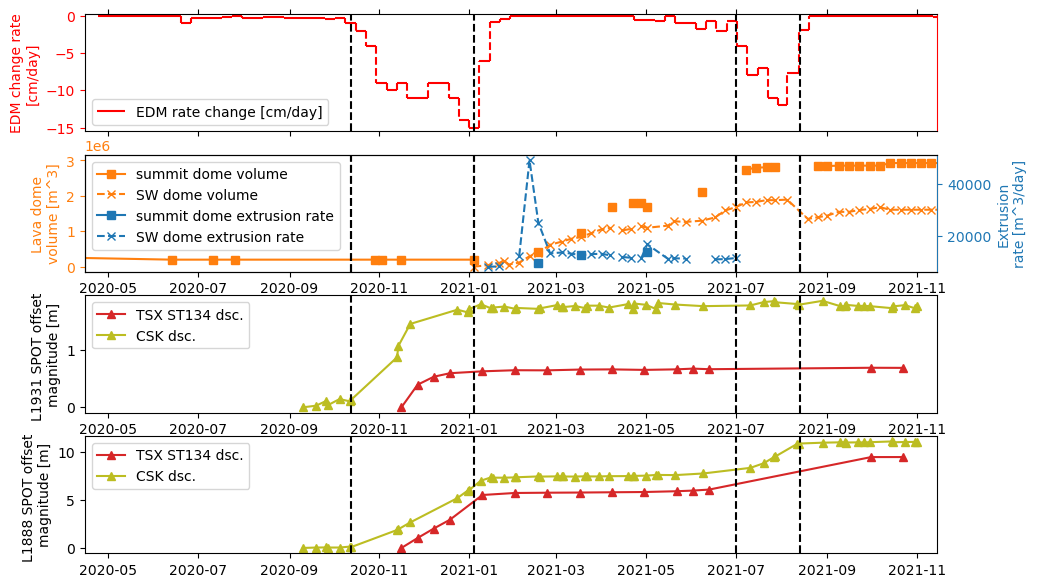

In [28]:
# 4 plot results

fig=plt.figure(figsize=(11,7))
gs=GridSpec(4,1)
ax0 = fig.add_subplot(gs[0,0]) # First row, first column
ax1 = fig.add_subplot(gs[1,0]) # second row, first column
ax2 = fig.add_subplot(gs[2,0]) # second row, first column
ax3 = fig.add_subplot(gs[3,0]) # second row, first column
# ax4 = fig.add_subplot(gs[4,0]) # second row, first column
# ax5 = fig.add_subplot(gs[5,0]) # second row, first column



ax0.set_ylabel('EDM change rate\n[cm/day]', color = 'red') 




ax0.hlines(y=EDM_rate[:-1], xmin=EDM_dates[:-1], xmax=EDM_dates[1:],
           color='red', zorder=1)
ax0.vlines(x=EDM_dates[1:], ymin=EDM_rate[:-1], ymax=EDM_rate[1:], color='red',
          linestyle='dashed', zorder=1)

ax0.set_ylim([-15.5,0.2])

ax0.tick_params(left=True,
                bottom=True,
                top=True,
                labelbottom=False,
                labeltop=False)

ax0.spines['right'].set_color('red')
ax0.yaxis.label.set_color('red')
ax0.tick_params(axis='y', colors='red')

##############################################################################################
##############################################################################################


x_lim_dates = ax0.get_xlim()

# # plot lava dome volume and dome growth rate
# # print(lava_dome_vol_rate.shape())
ax1.plot(lavadome_dates,lava_dome_vol_rate[:,0],color='tab:orange', marker='s',linestyle='-')
ax1.plot(lavadome_dates,lava_dome_vol_rate[:,2],color='tab:orange', marker='x',linestyle='--')

ax1_twin = ax1.twinx()
ax1_twin.plot(lavadome_dates,lava_dome_vol_rate[:,1],color='tab:blue', marker='s',linestyle='-')
ax1_twin.plot(lavadome_dates,lava_dome_vol_rate[:,3],color='tab:blue', marker='x',linestyle='--')


ax1.spines['right'].set_color('tab:orange')
ax1.yaxis.label.set_color('tab:orange')
ax1.tick_params(axis='y', colors='tab:orange')

ax1_twin.spines['right'].set_color('tab:blue')
ax1_twin.yaxis.label.set_color('tab:blue')
ax1_twin.tick_params(axis='y', colors='tab:blue')

ax1.set_xlim(x_lim_dates)
ax1.set_ylabel('Lava dome\nvolume [m^3]')
ax1_twin.set_ylabel('Extrusion\nrate [m^3/day]')


# ax0.fill_between(x= [],
#                      y1 = [],
#                      y2 = [],
#                      color = 'tab:blue',
#                      alpha = 0.5,
#                      label = 'EDM range BAD-RB1 \n[x+'+ str(EDM_dist_min_max[start_week,0]) + ' m]')
# ax0.fill_between(x= [],
#                      y1 = [],
#                      y2 = [],
#                      color = 'tab:orange',
#                      alpha = 0.5,
#                      label = 'EDM range BAD-RB2 \n[x+' + str(EDM_dist_min_max[start_week,2]) + ' m]')
ax0.hlines(y=[], xmin=[], xmax=[],
              color='red', zorder=1, label = 'EDM rate change [cm/day]')

ax0.legend(loc='lower left')


ax1.plot([],[],color='tab:orange', marker='s',linestyle='-', label='summit dome volume')
ax1.plot([],[],color='tab:orange', marker='x',linestyle='--', label='SW dome volume')
ax1.plot([],[],color='tab:blue', marker='s',linestyle='-', label='summit dome extrusion rate')
ax1.plot([],[],color='tab:blue', marker='x',linestyle='--', label='SW dome extrusion rate')

ax1.legend(loc='upper left')



##############################################################################################################
##############################################################################################################

TSX_L1931 = np.hypot(TSX_median_list[0][::2],TSX_median_list[0][1::2])
TSX_L1888 = np.hypot(TSX_median_list[2][::2],TSX_median_list[2][1::2])

CSK_L1931 = np.hypot(CSK_median_list[0][::2],CSK_median_list[0][1::2])
CSK_L1888 = np.hypot(CSK_median_list[2][::2],CSK_median_list[2][1::2])


ax2.plot(TSX_dates,TSX_L1931,marker='^',color='tab:red',label='TSX ST134 dsc.')
ax2.plot(CSK_dates,CSK_L1931,marker='^',color='tab:olive',label='CSK dsc.')

ax3.plot(TSX_dates,TSX_L1888,marker='^',color='tab:red',label='TSX ST134 dsc.')
ax3.plot(CSK_dates,CSK_L1888,marker='^',color='tab:olive',label='CSK dsc.')

ax2.set_ylabel('L1931 SPOT offset \nmagnitude [m]')
ax3.set_ylabel('L1888 SPOT offset \nmagnitude [m]')

ax2.legend()
ax3.legend()

for a in fig.axes:
    a.set_xlim([datetime.datetime(2020,4,15),datetime.datetime(2021,11,15)])
    a.axvline(x=datetime.datetime.strptime('2020-10-13','%Y-%m-%d'),linewidth=1.5,color='black',linestyle='--')
    a.axvline(x=datetime.datetime.strptime('2021-01-04','%Y-%m-%d'),linewidth=1.5,color='black',linestyle='--')
    a.axvline(x=datetime.datetime.strptime('2021-07-01','%Y-%m-%d'),linewidth=1.5,color='black',linestyle='--')
    a.axvline(x=datetime.datetime.strptime('2021-08-14','%Y-%m-%d'),linewidth=1.5,color='black',linestyle='--')

plt.show()